# Gradient Boosting Regression

**Learning objectives**
1. Reproduce the **three-tree classroom example** using `GradientBoostingRegressor`.
2. See the **initial mean prediction**, residuals, tree splits, and learning-rate updates.


.

## Part A — Our manual classroom example

We have six machines. We want to predict the number of units produced from operating hours.

**Settings:** 3 trees (`n_estimators=3`), one split per tree (`max_depth=1`), and a learning rate of 0.5. We use squared-error loss.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Classroom dataset
df = pd.DataFrame({
    "Hours": [1, 2, 3, 4, 5, 6],
    "Units": [20, 20, 20, 40, 40, 100]
})

X = df[["Hours"]]  # Must remain 2D
y = df["Units"]

print(df.to_string(index=False))

 Hours  Units
     1     20
     2     20
     3     20
     4     40
     5     40
     6    100


### Step 1 — Initial prediction = mean

For **squared-error regression**, the best single constant prediction is the mean target value. This is **before** fitting any correction trees.

In [2]:
initial_prediction = y.mean()
df["Initial_Prediction"] = initial_prediction
df["Initial_Residual"] = y - initial_prediction

print("Initial prediction (mean):", initial_prediction)
print(df.to_string(index=False))

Initial prediction (mean): 40.0
 Hours  Units  Initial_Prediction  Initial_Residual
     1     20                40.0             -20.0
     2     20                40.0             -20.0
     3     20                40.0             -20.0
     4     40                40.0               0.0
     5     40                40.0               0.0
     6    100                40.0              60.0


### Step 2 — Train the three correction trees

- The **first tree** learns the initial residuals.
- Subsequent trees learn the remaining residuals after previous corrections.
- Every tree's contribution is multiplied by the **learning rate**.

In [3]:
model = GradientBoostingRegressor(
    n_estimators=3,
    learning_rate=0.5,
    max_depth=1,
    loss="squared_error",
    random_state=42
)

model.fit(X, y)
print("Model trained successfully!")

Model trained successfully!


### Step 3 — Predictions after each tree

`staged_predict()` shows the **combined model prediction** after each boosting stage (not the raw output of only that tree).

In [4]:
result = pd.DataFrame({
    "Hours": X["Hours"],
    "Actual": y,
    "Initial": initial_prediction
})

for stage, predictions in enumerate(model.staged_predict(X), start=1):
    result[f"After_Tree_{stage}"] = predictions

print(result.round(2).to_string(index=False))

 Hours  Actual  Initial  After_Tree_1  After_Tree_2  After_Tree_3
     1      20     40.0          34.0          27.0          24.7
     2      20     40.0          34.0          27.0          24.7
     3      20     40.0          34.0          27.0          24.7
     4      40     40.0          34.0          41.0          38.7
     5      40     40.0          34.0          41.0          38.7
     6     100     40.0          70.0          77.0          88.5


### Step 4 — Examine each tree's split and leaf corrections

Because `max_depth=1`, each tree has one split. The leaf values are **corrections**, not final predictions.

In [5]:
for i, estimators_at_stage in enumerate(model.estimators_, start=1):
    tree = estimators_at_stage[0]  # One regression tree per stage for regression
    root = tree.tree_
    split = root.threshold[0]
    left_node = root.children_left[0]
    right_node = root.children_right[0]
    left_correction = root.value[left_node][0][0]
    right_correction = root.value[right_node][0][0]

    print(f"Tree {i}: split Hours <= {split:.1f}")
    print(f"  Left leaf correction:  {left_correction:.2f}")
    print(f"  Right leaf correction: {right_correction:.2f}")
    print()

Tree 1: split Hours <= 5.5
  Left leaf correction:  -12.00
  Right leaf correction: 60.00

Tree 2: split Hours <= 3.5
  Left leaf correction:  -14.00
  Right leaf correction: 14.00

Tree 3: split Hours <= 5.5
  Left leaf correction:  -4.60
  Right leaf correction: 23.00



### Step 5 — Check residuals and MSE at each stage

The residuals for the next tree are `Actual − Current prediction`. For this small training example, we expect the training MSE to decrease over the three stages.

In [6]:
previous_prediction = np.full(len(y), initial_prediction, dtype=float)
print(f"Initial MSE: {mean_squared_error(y, previous_prediction):.2f}")

for stage, current_prediction in enumerate(model.staged_predict(X), start=1):
    residual = y.to_numpy() - current_prediction
    print(f"\nAfter Tree {stage}:")
    print("Predictions:", np.round(current_prediction, 2))
    print("Residuals:  ", np.round(residual, 2))
    print(f"MSE: {mean_squared_error(y, current_prediction):.2f}")
    previous_prediction = current_prediction

Initial MSE: 800.00

After Tree 1:
Predictions: [34. 34. 34. 34. 34. 70.]
Residuals:   [-14. -14. -14.   6.   6.  30.]
MSE: 260.00

After Tree 2:
Predictions: [27. 27. 27. 41. 41. 77.]
Residuals:   [-7. -7. -7. -1. -1. 23.]
MSE: 113.00

After Tree 3:
Predictions: [24.7 24.7 24.7 38.7 38.7 88.5]
Residuals:   [-4.7 -4.7 -4.7  1.3  1.3 11.5]
MSE: 33.65


### Step 6 — Plot actual values and stage-wise predictions

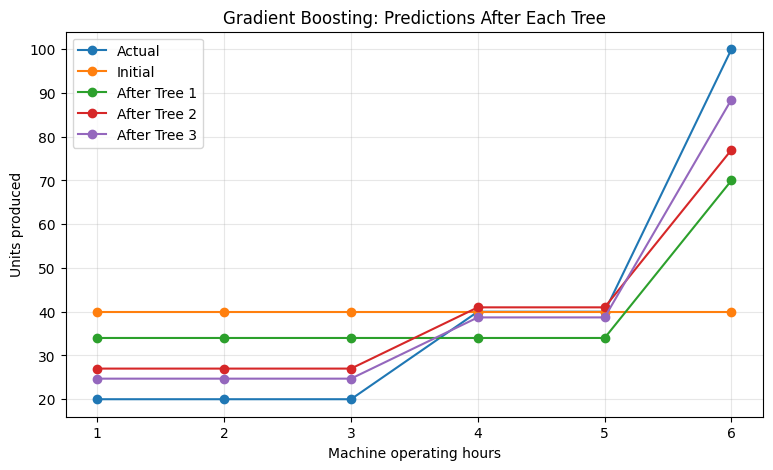

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(X["Hours"], y, marker="o", label="Actual")
plt.plot(X["Hours"], np.full(len(y), initial_prediction), marker="o", label="Initial")

for stage, predictions in enumerate(model.staged_predict(X), start=1):
    plt.plot(X["Hours"], predictions, marker="o", label=f"After Tree {stage}")

plt.xlabel("Machine operating hours")
plt.ylabel("Units produced")
plt.title("Gradient Boosting: Predictions After Each Tree")
plt.xticks(X["Hours"])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Step 7 — Predict for a new observation

A tree predicts a **constant value in each leaf**. Thus, new observations receive the correction assigned to their leaves. Gradient Boosting adds all the scaled corrections to the initial prediction.

In [8]:
new_data = pd.DataFrame({"Hours": [4, 6]})
new_data["Predicted_Units"] = model.predict(new_data)
print(new_data.round(2).to_string(index=False))

 Hours  Predicted_Units
     4             38.7
     6             88.5
